# A1 · Cold store: from the PLC signals to the answer to the customer (PySharp)

The same analysis as the [C#](A1-magazzino-frigorifero-csharp.ipynb) notebook, with the library's `Interop` facade and `matplotlib` charts (PySharp): **the same numbers**, verified by a test. `pysharp` kernel on .NET 11.

## The case

A **cold store** at +2 °C holds goods belonging to a customer (a food company). The plant's PLC sends to a historian, every minute, the chamber temperature, the door and defrost state, the compressor current, the suction pressure and the vibration. A meter sends the kWh every hour.

**Who works on the data.** The *quality manager* must be able to certify that the cold chain was not broken (HACCP threshold +4 °C). The *maintenance technician* wants to know in advance whether the compressor is failing. The *plant manager* must estimate next week's energy consumption. The *customer* asks: **“was my merchandise always below +4 °C?”**

**The data are synthetic**, generated by `generate-data.cs` with a seed: they serve to check the results against the known truth (`data/verita.json`), which is never possible with real data.

| Step | Question | Tool |
|---|---|---|
| 1 | Is the data complete? | data quality |
| 2 | What is the *true* temperature when the sensor is silent? | Kalman filter with `NaN` ([ch. 6](../../../../refs/timeseries/00-formule-e-libreria/06-kalman.md)) |
| 3 | How much energy will we consume? | seasonal naive, Holt-Winters, MASE ([ch. 3](../../../../refs/timeseries/00-formule-e-libreria/03-riferimenti-e-metriche.md), [5](../../../../refs/timeseries/00-formule-e-libreria/05-smoothing.md)) |
| 4 | Is the compressor failing? | GARCH on the vibration ([ch. 8](../../../../refs/timeseries/00-formule-e-libreria/08-garch.md)) |
| 5 | How do temperature, current and pressure influence each other? | VAR ([ch. 7](../../../../refs/timeseries/00-formule-e-libreria/07-var.md)) |
| 6 | KPIs, dashboard and answer to the customer | tiles, charts, text with the numbers |

In [ ]:
import os, math, clr
import matplotlib.pyplot as plt

# The working directory must be inside the MathemaSharp repository (scripts/run-notebooks.ps1 starts from the root).
root = os.getcwd()
while not os.path.exists(os.path.join(root, "src", "MathemaSharp.slnx")):
    parent = os.path.dirname(root)
    if parent == root:
        raise RuntimeError("Run the notebook with the working directory inside the MathemaSharp repository.")
    root = parent
clr.AddReference("D:/Dev/BuildArtifacts/MathemaSharp/bin/MathemaSharp.TimeSeries/release/MathemaSharp.TimeSeries.dll")
from MathemaSharp.TimeSeries.Interop import Forecasts, Metrics, Smoothing, Kalman, Var, Garch

def P(label, values):
    if isinstance(values, (int, float)):
        values = [values]
    print(label + ": " + " ".join("%.6f" % v for v in values))

def num(s):
    return float("nan") if s == "" else float(s)

def read_rows(name):
    f = open(os.path.join(data, name))
    text = f.read()
    f.close()
    return [l.split(",") for l in text.split(chr(10))[1:] if l.strip() != ""], text

data = os.path.join(root, "scenari", "A-magazzino-frigorifero", "data")
rows, _ = read_rows("cella_1min.csv")
temp = [num(r[1]) for r in rows]
current = [num(r[5]) for r in rows]
pressure = [num(r[6]) for r in rows]
vib = [num(r[7]) for r in rows]
limit = 4.0   # HACCP threshold, degrees C

## 1 · Acquire: is the data complete?
A communication gap is not a zero reading: it is an **absent** reading. Before any calculation, measure how much is missing and where.

In [ ]:
gaps = []
i = 0
while i < len(temp):
    if not math.isnan(temp[i]):
        i += 1
        continue
    j = i
    while j < len(temp) and math.isnan(temp[j]):
        j += 1
    gaps.append((i, j - i))
    i = j + 1
gap_minutes = sum([g[1] for g in gaps])
P("samples", len(temp))
P("gaps_n", len(gaps))
P("missing_min", gap_minutes)
P("max_gap_min", max([g[1] for g in gaps]))

# A gap is "suspect" if the temperature at its edges differs by more than 1 degree: something happened during the gap.
suspect = [g for g in gaps if g[0] > 0 and g[0] + g[1] < len(temp) and abs(temp[g[0] + g[1]] - temp[g[0] - 1]) > 1.0]
suspect_minutes = sum([g[1] for g in suspect])
P("suspect_gaps_min", suspect_minutes)

samples: 4320.000000
gaps_n: 6.000000
missing_min: 70.000000
max_gap_min: 20.000000
suspect_gaps_min: 12.000000


## 2 · Understand the temperature: the Kalman filter
The sensor has a known noise (σ = 0.08 °C, from the datasheet). The *local level* model treats the true temperature as a hidden state that moves a little every minute (variance $q$); the `NaN`s skip the correction. The variance $q$ is chosen by maximising the **log-likelihood** on a grid.

In [ ]:
sensor_variance = 0.08 * 0.08
q_grid = [0.001, 0.003, 0.01, 0.03, 0.1]
log_lik = [Kalman.Filter(Kalman.LocalLevel(q, sensor_variance, temp[0], 1.0), temp).LogLikelihood for q in q_grid]
P("kalman_loglik_grid", log_lik)
q_best = q_grid[log_lik.index(max(log_lik))]
P("kalman_q", q_best)

level = list(Kalman.Filter(Kalman.LocalLevel(q_best, sensor_variance, temp[0], 1.0), temp).FilteredFirstState)
trend = list(Kalman.Filter(Kalman.LocalLinearTrend(q_best, q_best / 10, sensor_variance, temp[0], 0.0, 1.0), temp).FilteredFirstState)

kalman_loglik_grid: -646.218827 2049.143120 2688.980428 2051.162914 435.282661
kalman_q: 0.010000


### The HACCP KPI: how many minutes above +4 °C?
Four answers to the same question. **The rise happens inside a communication gap**, so no tool sees all of it: the only honest answer is an **interval**.

In [ ]:
def above(x):
    return sum([1 for v in x if v > limit])

def runs(x):
    n = 0
    for i in range(len(x)):
        if x[i] > limit and (i == 0 or x[i - 1] <= limit):
            n += 1
    return n

observed = sum([1 for v in temp if (not math.isnan(v)) and v > limit])
P("haccp_observed_min", observed)
P("haccp_kalman_level_min", above(level))
P("haccp_kalman_trend_min", above(trend))
P("haccp_kalman_excursions", runs(level))
P("filtered_temp_max", max(level))
P("haccp_interval_min", [observed, observed + suspect_minutes])

# Truth: only the generator of the synthetic data knows it, not a real historian.
import json
f = open(os.path.join(data, "verita.json"))
truth = json.loads(f.read())
f.close()
truth_minutes = truth["minuti_veri_sopra_soglia"]
P("haccp_truth_min", truth_minutes)
P("haccp_truth_in_interval", 1 if (truth_minutes >= observed and truth_minutes <= observed + suspect_minutes) else 0)

haccp_observed_min: 7.000000
haccp_kalman_level_min: 8.000000
haccp_kalman_trend_min: 9.000000
haccp_kalman_excursions: 1.000000
filtered_temp_max: 4.494347
haccp_interval_min: 7.000000 19.000000
haccp_truth_min: 11.000000
haccp_truth_in_interval: 1.000000


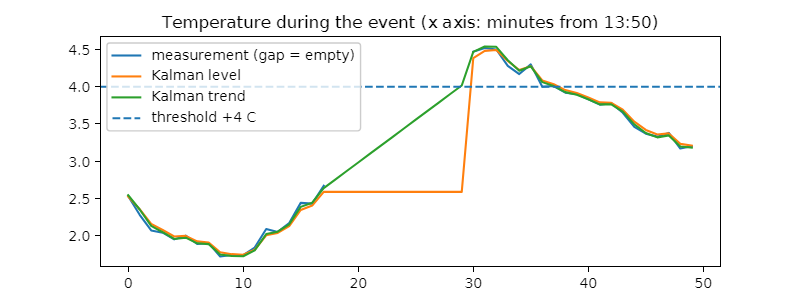

In [ ]:
# The event: Tuesday 15 September, from 13:50 to 14:40.
a = 1440 + 13 * 60 + 50
b = 1440 + 14 * 60 + 40
xs = list(range(b - a))
plt.figure(figsize=(8, 3))
plt.plot(xs, temp[a:b], label="measurement (gap = empty)")
plt.plot(xs, level[a:b], label="Kalman level")
plt.plot(xs, trend[a:b], label="Kalman trend")
plt.axhline(limit, linestyle="--", label="threshold +4 C")
plt.title("Temperature during the event (x axis: minutes from 13:50)")
plt.legend()
plt.show()

## 3 · Forecast next week's energy
Six weeks of hourly kWh: five for training, the last one as a **test the model has never looked at**. The comparison is with the MASE relative to the weekly seasonal naive ($m=168$): below 1 the model beats the reference.

In [ ]:
erows, _ = read_rows("energia_oraria.csv")
kwh = [num(r[1]) for r in erows]
train, test = kwh[:840], kwh[840:]

candidates = [
    ("sn24", list(Forecasts.SeasonalNaive(train, 24, 168))),
    ("sn168", list(Forecasts.SeasonalNaive(train, 168, 168))),
    ("hw24", list(Smoothing.HoltWinters(train, 24, 0.2, 0.01, 0.2, 168, 1.0).Forecast)),
    ("hw168", list(Smoothing.HoltWinters(train, 168, 0.2, 0.01, 0.2, 168, 1.0).Forecast)),
]
for name, fc in candidates:
    P("mase_" + name, Metrics.Mase(test, fc, train, 168))
    P("kwh_week_" + name, sum(fc))
test_total = sum(test)
P("kwh_week_actual", test_total)
for name, fc in candidates:
    P("kwh_error_pct_" + name, 100 * (sum(fc) - test_total) / test_total)
best_name, best_forecast = min(candidates, key=lambda c: Metrics.Mase(test, c[1], train, 168))
print("chosen_model: " + best_name)

mase_sn24: 1.870867
kwh_week_sn24: 6478.850000
mase_sn168: 0.918371
kwh_week_sn168: 7119.510000
mase_hw24: 1.903675
kwh_week_hw24: 6360.663626
mase_hw168: 0.933787
kwh_week_hw168: 7414.558830
kwh_week_actual: 7395.980000
kwh_error_pct_sn24: -12.400385
kwh_error_pct_sn168: -3.738112
kwh_error_pct_hw24: -13.998366
kwh_error_pct_hw168: 0.251202
chosen_model: sn168


> **Two criteria, two answers.** For the **hourly profile** (MASE) the weekly seasonal naive wins; for the **weekly total** (the energy budget) Holt-Winters is the one that errs less. And with **a single test week** the choice of the model and its evaluation coincide: the result is optimistic. Serious validation repeats the test on many origins (*rolling origin*): it is among the book's theories not yet implemented.

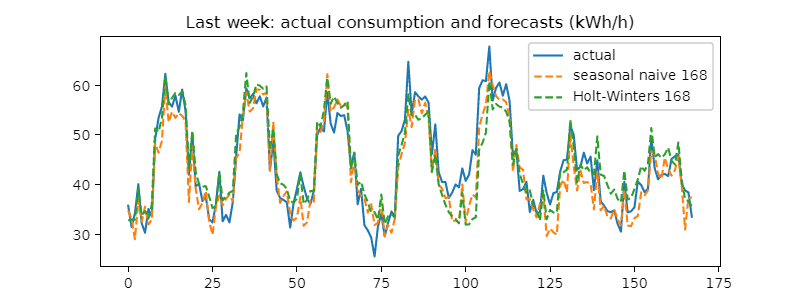

In [ ]:
plt.figure(figsize=(8, 3))
plt.plot(range(168), test, label="actual")
plt.plot(range(168), candidates[1][1], linestyle="--", label="seasonal naive 168")
plt.plot(range(168), candidates[3][1], linestyle="--", label="Holt-Winters 168")
plt.title("Last week: actual consumption and forecasts (kWh/h)")
plt.legend()
plt.show()

## 4 · Is the compressor failing? The volatility of the vibration
The vibration depends on the compressor state (on/off). Once the level of each state is removed, what remain are shocks whose **variance** says how “restless” the compressor is. The GARCH is trained on the **first 48 hours** (normal behaviour) and then the conditional volatility is read over the following 24 hours.

In [ ]:
on = [c > 10 for c in current]

def mean_state(state):
    s = 0.0
    n = 0
    for i in range(2880):
        if on[i] == state:
            s += vib[i]
            n += 1
    return s / n

m_on = mean_state(True)
m_off = mean_state(False)
P("vib_level_on_off", [m_on, m_off])
residual = [v - (m_on if on[i] else m_off) for i, v in enumerate(vib)]

garch = Garch.FitVarianceTargeting(residual[:2880])
P("garch_fit", [garch.Omega, garch.Alpha, garch.Beta])
sigma_bar = math.sqrt(garch.UnconditionalVariance)
P("garch_sigma_base", sigma_bar)
sigma = [math.sqrt(v) for v in garch.ConditionalVariances(residual)]
alarm = [s > 1.5 * sigma_bar for s in sigma]

def rate(first, last):
    return sum([1 for i in range(first, last) if alarm[i]]) / (last - first)

P("alarm_day1", rate(0, 1440))
P("alarm_day2", rate(1440, 2880))
P("alarm_day3", rate(2880, 4320))

# Sustained alarm: at least 8 minutes above the threshold in the last hour (60-minute sliding window).
first_alarm = -1
window = 0
for i in range(len(alarm)):
    if alarm[i]:
        window += 1
    if i >= 60 and alarm[i - 60]:
        window -= 1
    if window >= 8 and first_alarm < 0:
        first_alarm = i
P("alarm_first_minute", first_alarm)
P("alarm_delay_min", first_alarm - 2880)   # the true change is at minute 2880 (48 h): negative = false alarm

vib_level_on_off: 2.599607 0.400610
garch_fit: 0.001890 0.082975 0.809350
garch_sigma_base: 0.132491
alarm_day1: 0.004861
alarm_day2: 0.002083
alarm_day3: 0.227083
alarm_first_minute: 2951.000000
alarm_delay_min: 71.000000


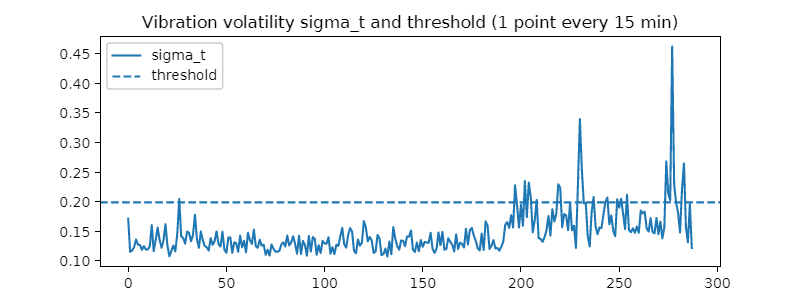

In [ ]:
plt.figure(figsize=(8, 3))
plt.plot(range(0, len(sigma) // 15), [sigma[i * 15] for i in range(len(sigma) // 15)], label="sigma_t")
plt.axhline(1.5 * sigma_bar, linestyle="--", label="threshold")
plt.title("Vibration volatility sigma_t and threshold (1 point every 15 min)")
plt.legend()
plt.show()

## 5 · Coupled signals: VAR
5-minute means of temperature (filtered), current and pressure. The VAR(1) answers: *how much does the current now predict the temperature five minutes from now?*

In [ ]:
step = 5
n5 = len(temp) // step
flat = []
for k in range(n5):
    st = 0.0
    sc = 0.0
    sp = 0.0
    for j in range(step):
        st += level[k * step + j]
        sc += current[k * step + j]
        sp += pressure[k * step + j]
    flat.extend([st / step, sc / step, sp / step])
var3 = Var.Fit(flat, n5, 3, 1)
P("var_a1", list(Var.Coefficient(var3, 1)))

var_a1: 0.841806 -0.032525 -0.068756 9.057558 0.728416 3.997443 -0.463599 -0.038371 -0.227008


Reading of $A_1$ (rows = equations, columns = temperature, current, pressure at the previous step): **temperature ← current** is negative (compressor on ⇒ the chamber cools); **current ← temperature** is strongly positive (warm chamber ⇒ the thermostat switches the compressor on). From the data alone, the VAR rediscovers the logic of the thermostat.

## 6 · Communicate: KPIs, dashboard and answer to the customer

In [ ]:
STATUS = {"ok": "&#10003; normal", "warn": "&#9650; warning", "alarm": "&#10006; alarm", "": ""}

def tiles(items):
    html = '<div style="display:grid;grid-template-columns:repeat(auto-fit,minmax(170px,1fr));gap:8px;font-family:system-ui,sans-serif">'
    for label, value, note, status in items:
        html += '<div style="background:#fcfcfb;border:1px solid #e4e3df;border-radius:8px;padding:10px 12px">'
        html += '<div style="font-size:12px;color:#52514e">' + label + '</div>'
        html += '<div style="font-size:26px;font-weight:600;color:#0b0b0b;line-height:1.2">' + value + '</div>'
        html += '<div style="font-size:12px;color:#52514e">' + note + '</div>'
        if STATUS[status] != "":
            html += '<div style="font-size:12px;font-weight:600;color:#0b0b0b;margin-top:2px">' + STATUS[status] + '</div>'
        html += '</div>'
    display_html(html + '</div>')

def quote(title, text):
    display_html('<div style="background:#fcfcfb;border-left:4px solid #2a78d6;padding:10px 14px;margin:8px 0;font-family:system-ui,sans-serif;color:#0b0b0b"><div style="font-size:12px;color:#52514e">' + title + '</div><div style="font-size:14px">' + text + '</div></div>')

energy_next = sum(best_forecast)
alarm_day3 = rate(2880, 4320)
day1 = rate(0, 1440)
upper = observed + suspect_minutes
mase_best = Metrics.Mase(test, best_forecast, train, 168)
energy_error = 100 * (energy_next - test_total) / test_total

tiles([
    ("Time above +4 &deg;C", "%d&ndash;%d min" % (observed, upper), "minimum observed &ndash; maximum not excludable", "warn"),
    ("HACCP excursions", "%d" % runs(level), "maximum estimated temperature %.1f &deg;C" % max(level), "warn"),
    ("Missing data", "%.1f %%" % (100.0 * gap_minutes / len(temp)), "%d gaps, the longest %d min" % (len(gaps), max([g[1] for g in gaps])), "ok"),
    ("Energy next week", "%.0f kWh" % energy_next, "model %s, MASE %.2f; on the total %+.1f %% in the test week" % (best_name, mase_best, energy_error), "ok"),
    ("Compressor vibration", "%.0f %% alarm" % (100 * alarm_day3), "last 24 h, against %.1f %% on the first day; first alarm %d min after the change" % (100 * day1, first_alarm - 2880), "alarm" if alarm_day3 > 0.2 else "ok"),
])

Time above +4 °C 7–19 min minimum observed – maximum not excludable ▲ warning HACCP excursions 1 maximum estimated temperature 4.5 °C ▲ warning Missing data 1.6 % 6 gaps, the longest 20 min ✓ normal Energy next week 7120 kWh model sn168, MASE 0.92; on the total -3.7 % in the test week ✓ normal Compressor vibration 23 % alarm last 24 h, against 0.5 % on the first day; first alarm 71 min after the change ✖ alarm

Answer to the customer: was my merchandise always below +4 C? In the 72 hours from 14 to 16 September the chamber temperature was observed above +4 C for at least 7 minutes, in 1 excursion, with an estimated maximum of 4.5 C (Tuesday afternoon). For 12 minutes the sensor did not communicate and the temperature at the edges of the gap differed by more than 1 C: we cannot exclude further minutes above the threshold, up to a maximum of 19. For this reason our answer is not always below +4 C, but from 7 to 19 minutes above the threshold in a single excursion; we propose checking the chamber door and the communication gateway.

Note for maintenance The volatility of the compressor vibration is above the threshold for 23 % of the last day (against 0.5 % on the first). The sustained alarm went off 71 minutes after the change began: a bearing check is recommended.

In [ ]:
answer = ("In the 72 hours from 14 to 16 September the chamber temperature was observed above +4 C for at least %d minutes, in %d excursion, with an estimated maximum of %.1f C (Tuesday afternoon). " % (observed, runs(level), max(level))
    + "For %d minutes the sensor did not communicate and the temperature at the edges of the gap differed by more than 1 C: we cannot exclude further minutes above the threshold, up to a maximum of %d. " % (suspect_minutes, upper)
    + "For this reason our answer is not always below +4 C, but from %d to %d minutes above the threshold in a single excursion; we propose checking the chamber door and the communication gateway." % (observed, upper))
quote("Answer to the customer: was my merchandise always below +4 C?", answer)

maintenance = ("The volatility of the compressor vibration is above the threshold for %.0f %% of the last day (against %.1f %% on the first). " % (100 * alarm_day3, 100 * day1)
    + "The sustained alarm went off %d minutes after the change began: a bearing check is recommended." % (first_alarm - 2880))
quote("Note for maintenance", maintenance)

## What we learned
- **A gap in the data is information**: the HACCP KPI is given as an interval, and the known truth (11 minutes) falls inside it.
- **The Kalman filter does its job but does not guess**: it does not see a rise that happened entirely inside the gap, neither with the level alone nor with the trend.
- **GARCH as a bell**: it does not say *what* is failing, it says that the behaviour has changed; the alarm does not coincide with the change (*change time is not alarm time*).
- **The same numbers in C# and PySharp**: same library, same answer, a language of the choice of whoever works on the plant.